# Comparing the tests on legnini

Four ways to answer the same question on the same genes and the same expression layer: does a gene change differently with the distance to SHH+ cells in Ctrl and SHH slides?

| | Test | Fitted to | Inference | Slides | p-value |
|---|---|---|---|---|---|
| 1 | Wald | bins (sliding windows) | NUTS | ignored | Gamma null fitted to the panel |
| 2 | Curve test | bins (contiguous, weighted by cell count) | NUTS | ignored | per gene, noncentral chi-square |
| 3 | Curve test | cells | ADVI | ignored | per gene, noncentral chi-square |
| 4 | Curve test | cells | ADVI | empirical-Bayes random effects | per gene, noncentral F |

What the two tests look at:

* **Wald** (`test="wald"`) compares the two posterior-predictive condition curves. Its p-value comes from `T`, the mean squared gap between the curves, against a Gamma distribution fitted to the lower 90% of the panel. So `T` contains level differences as well as shape differences, and the p-value depends on which other genes are in the panel.
* **Curve test** (`test="parallel"`) is a Wald test on the interaction coefficients (`parallel_stat`), restricted to the directions that change the shape of the gap, against an interval null: `shape_diff <= tau`. Level differences do not enter, and the p-value is per gene, so no panel is needed.

Tests 2 and 3 are the same model on the same likelihood, once on weighted bins and once on cells, so they should agree. Tests 3 and 4 differ only in the slide effects.

Each test gets its ranked table, p-value histogram and volcano plot. The last section compares the four rankings.

**Runtime:** the slide model on cells is by far the slowest part, about 34 min with 4 workers on this data, against 3-7 min for each of the others. Run it on the cluster (`test_comparison_legnini.sbatch`), or shorten `GENES` for a trial, keeping 10 or more genes for the Gamma null.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
# This has to happen before numpy is imported, so restart the kernel if numpy is already loaded.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

/ictstr01/groups/ml01/workspace/laurens.lehner/tools/apps/miniforge/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data and anchor

Cells in the top percentile of SHH expression are the anchor. Every other cell gets its distance to the closest SHH+ cell of its own slide, scaled to 0-1 per slide. `slide1_A2-2` has no SHH+ cells, so it drops out of the fits.

In [2]:
adata = sc.read_h5ad(os.environ.get("DIFFSVG_DATA", "/home/lehnerl/Arbeit/data/legnini23.h5ad"))

shh = adata[:, "SHH"].X
shh = (shh.toarray() if hasattr(shh, "toarray") else np.asarray(shh)).ravel()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(adata, cluster_key="SHH+", groups="True", library_key="sample", covariates="condition")
adata.obsm["design_matrix"].head()

,SHH+,sample,True,True_raw,condition
0,False,slide1_A2-1,0.045167,97.930591,SHH
1,False,slide1_A2-1,0.404672,877.397221,SHH
2,True,slide1_A2-1,NaN,0.000000,SHH
3,False,slide1_A2-1,0.121246,262.882032,SHH
4,False,slide1_A2-1,0.149174,323.433256,SHH


## Settings

* `LAYER`: the Normal likelihood suits log-transformed data.
* `TAU`: the smallest shape difference that counts for the curve test, in slope-equivalent units. With `TAU > 0`, genes clearly below it get p-values near 1, so the histogram has a second peak there by design.
* `TOP_N`: the size of the top list in the comparison.

In [3]:
LAYER = "log1p_norm"
GENES = list(adata.var_names)  # shorten for a trial run (keep 10+ genes for the Gamma null)
N_WORKERS = int(os.environ.get("DIFFSVG_WORKERS", 4))
TAU = 0.1
TOP_N = 20
RESULTS_PATH = os.environ.get("DIFFSVG_RESULTS", "test_comparison_legnini_results.pkl")

results, ranks, timings = {}, {}, {}

In [4]:
PVALUE = {"wald": ("gamma_pval", "gamma_pval_adj", "T"), "parallel": ("parallel_pval", "parallel_pval_adj", "parallel_stat")}
COLUMNS = {
    "wald": ["T", "wald_stat", "gamma_pval", "gamma_pval_adj", "integral"],
    "parallel": ["shape_diff", "slope_diff", "parallel_stat", "parallel_pval", "parallel_pval_adj", "integral"],
}


def passes_diagnostics(stats):
    """Whether the fit of each gene can be trusted: R-hat for NUTS, the importance-sampling checks for ADVI."""
    if "vi_khat" not in stats:
        return stats["rhat_max"] < 1.05
    min_ess = 0.1 if "sample_level_sd" in stats else 0.5  # the ESS share falls with the number of parameters
    return (stats["vi_khat"] < 0.7) & (stats["vi_ess"] > min_ess)


def run_test(name, test, binning=None, **fit_kwargs):
    """Bin, fit and rank; every test keeps its own tables in `adata.varm`, so its curves can be plotted later."""
    key = f"test{len(results) + 1}"
    t0 = time.perf_counter()
    dvg.pp.bin_obs(adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, **(binning or {}))
    dvg.tl.fit_model(
        adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, test=test, tau=TAU,
        stats_key=f"{key}_stats", preds_key=f"{key}_preds", curves_key=f"{key}_curves", coefs_key=f"{key}_coefs",
        **fit_kwargs,
    )  # fmt: skip
    timings[name] = time.perf_counter() - t0

    stats = adata.varm[f"{key}_stats"].loc[GENES].copy()
    stats["passes_diagnostics"] = passes_diagnostics(stats)
    pvalue, _, statistic = PVALUE[test]
    # Ordered by p-value, with ties (p-values that underflow to 0, or sit at 1) broken by the larger statistic.
    table = stats.sort_values([pvalue, statistic], ascending=[True, False])
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    results[name], ranks[name] = table, table["rank"]
    print(f"{timings[name]:.0f} s, {stats['passes_diagnostics'].sum()} of {len(stats)} genes pass the diagnostics")
    return table[["rank", *COLUMNS[test], "passes_diagnostics"]]


def qc_plots(name, test):
    """p-value histogram next to the volcano plot."""
    pvalue, pvalue_adj, _ = PVALUE[test]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    dvg.pl.plot_pvalue_histogram(results[name], pvalue=pvalue, ax=axes[0])
    dvg.pl.plot_volcano(results[name], pvalue=pvalue, pvalue_adj=pvalue_adj, ax=axes[1], n_label=15)
    fig.suptitle(name)
    fig.tight_layout()

## 1. Wald test on bins, NUTS

Sliding windows of radius 0.02 around 51 grid points (the `bin_obs` defaults), one model per gene, sampled with NUTS.

In [5]:
NAME_1 = "1: Wald, bins, NUTS"
run_test(NAME_1, "wald").head(25)

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models:   1%|          | 1/88 [02:46<4:01:41, 166.69s/it]

Fitting DiffSVG models:  15%|█▍        | 13/88 [03:11<13:57, 11.17s/it]  

Fitting DiffSVG models:  16%|█▌        | 14/88 [03:12<12:25, 10.07s/it]

Fitting DiffSVG models:  18%|█▊        | 16/88 [03:12<09:23,  7.83s/it]

Fitting DiffSVG models:  19%|█▉        | 17/88 [03:12<08:01,  6.78s/it]

... (55 outputs left out)

Fitting DiffSVG models:  97%|█████████▋| 85/88 [08:16<01:11, 23.90s/it]

Fitting DiffSVG models: 100%|██████████| 88/88 [08:16<00:00,  5.65s/it]

498 s, 81 of 88 genes pass the diagnostics


,rank,T,wald_stat,gamma_pval,gamma_pval_adj,integral,passes_diagnostics
PAX7,1,4.900165,66880.190568,2.664535e-15,2.344791e-13,-2.173225,True
NKX6.1,2,4.637782,34322.863525,1.398881e-14,6.155076e-13,2.100800,True
Circ.RMST,3,1.890928,18005.412728,5.676033e-07,1.322996e-05,-1.329077,True
IRX3,4,1.882041,17679.499294,6.013617e-07,1.322996e-05,-1.351899,True
GLI3,5,0.685571,4247.847670,1.770592e-03,3.116242e-02,-0.810396,True
NEUROG2,6,0.534480,8344.480179,5.170777e-03,7.583807e-02,0.640881,True
GLI2,7,0.458610,3860.506299,8.975674e-03,1.128370e-01,-0.639161,True
PAX6,8,0.431861,2799.643916,1.093272e-02,1.202599e-01,-0.551449,True
PTPRZ1,9,0.271367,3692.122378,3.734583e-02,3.540590e-01,-0.482887,True
MSX2,10,0.262062,6911.116778,4.023397e-02,3.540590e-01,-0.481705,True


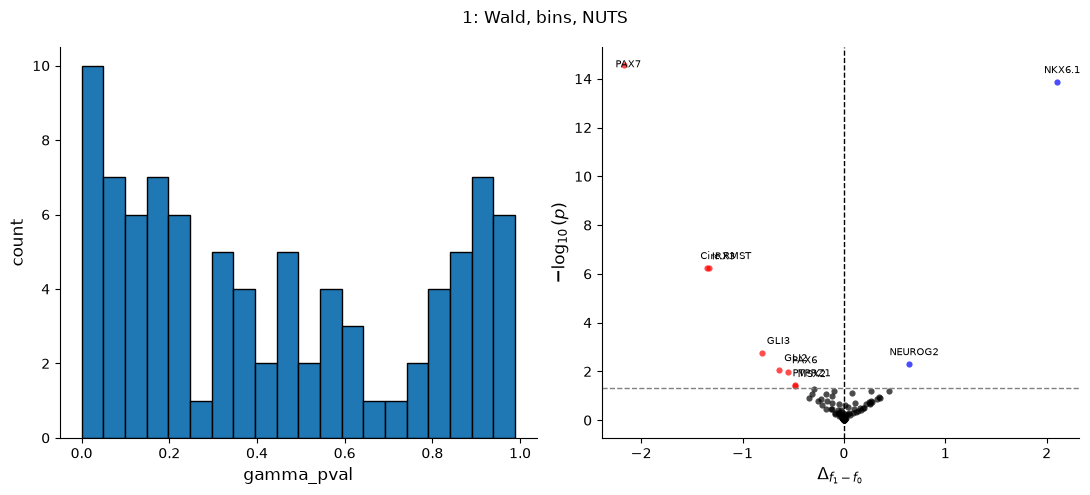

In [6]:
qc_plots(NAME_1, "wald")

## 2. Curve test on bins, NUTS

Contiguous bins (`window_radius=None`), so every cell counts once and each bin is weighted by its cell count. The curve test needs this: on the overlapping windows of test 1, neighbouring bins share cells and the p-values come out too small.

In [7]:
NAME_2 = "2: Curve test, bins, NUTS"
run_test(NAME_2, "parallel", binning={"window_radius": None}).head(25)

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models:   1%|          | 1/88 [00:26<38:47, 26.75s/it]

Fitting DiffSVG models:   2%|▏         | 2/88 [00:27<16:14, 11.34s/it]

Fitting DiffSVG models:   3%|▎         | 3/88 [00:30<10:58,  7.75s/it]

Fitting DiffSVG models:   5%|▍         | 4/88 [00:31<06:50,  4.88s/it]

Fitting DiffSVG models:   6%|▌         | 5/88 [01:00<19:08, 13.84s/it]

... (63 outputs left out)

Fitting DiffSVG models: 100%|██████████| 88/88 [05:09<00:00,  1.51s/it]

Fitting DiffSVG models: 100%|██████████| 88/88 [05:09<00:00,  3.51s/it]

310 s, 85 of 88 genes pass the diagnostics


,rank,shape_diff,slope_diff,parallel_stat,parallel_pval,parallel_pval_adj,integral,passes_diagnostics
PAX7,1,1.746448,-1.041735,6210.132544,0.000000e+00,0.000000e+00,-2.169810,True
HHIP,2,1.458948,1.012011,3785.437325,0.000000e+00,0.000000e+00,-0.100931,True
GLI1,3,1.269747,0.940283,3215.573263,0.000000e+00,0.000000e+00,0.270300,True
DBX2,4,0.934328,0.482494,2022.395635,0.000000e+00,0.000000e+00,-0.309085,True
DBX1,5,1.289206,0.697240,1866.339711,0.000000e+00,0.000000e+00,-0.177376,True
FOXA2,6,0.963268,0.467126,1840.010900,0.000000e+00,0.000000e+00,-0.001639,True
PTCH1,7,1.427388,0.500511,1538.643843,5.598219e-277,7.037761e-276,0.079367,True
AC129492.1,8,1.274193,-1.073527,1546.130764,7.288096e-273,8.016905e-272,-0.115588,True
FOS,9,0.970605,-0.613972,1449.135652,2.103761e-240,2.057011e-239,-0.050059,True
MSX2,10,0.649827,-0.542330,1689.343936,5.551675e-238,4.885474e-237,-0.480149,True


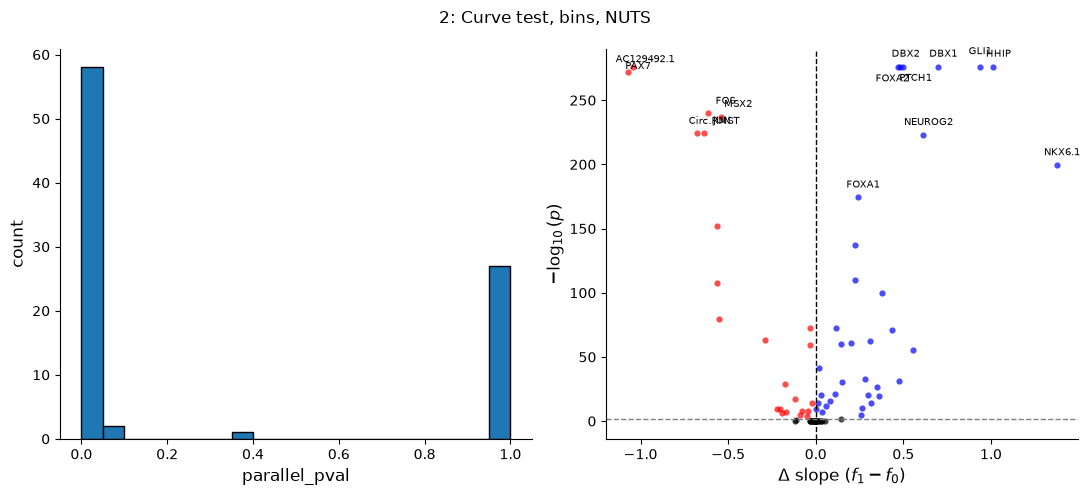

In [8]:
qc_plots(NAME_2, "parallel")

## 3. Curve test on cells, ADVI

The same test on every cell, with full-rank ADVI (Laplace start, Adam polish). `bin_obs` only provides the spline basis and the prediction grid here. Cells of a condition are pooled, so differences between slides count as differences between conditions, and with this many cells the test can only be held back by `tau`.

In [9]:
NAME_3 = "3: Curve test, cells, ADVI"
run_test(NAME_3, "parallel", binning={"window_radius": None}, use_binned=False, inference="advi").head(25)

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models:   1%|          | 1/88 [01:20<1:57:21, 80.93s/it]

Fitting DiffSVG models:  11%|█▏        | 10/88 [01:21<07:37,  5.86s/it] 

/ictstr01/groups/ml01/workspace/laurens.lehner/tools/apps/miniforge/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting DiffSVG models:  11%|█▏        | 10/88 [01:35<07:37,  5.86s/it]

Fitting DiffSVG models:  14%|█▎        | 12/88 [01:48<09:39,  7.62s/it]

... (32 outputs left out)

Fitting DiffSVG models: 100%|██████████| 88/88 [04:35<00:00,  3.13s/it]

/tmp/ipykernel_1096413/503169217.py:21: UserWarning: 3 of 88 genes fail the variational diagnostics (expected: vi_khat < 0.7 and vi_ess > 0.5), so the approximation does not match the posterior for them: do not read their p-values.
  dvg.tl.fit_model(


277 s, 85 of 88 genes pass the diagnostics


,rank,shape_diff,slope_diff,parallel_stat,parallel_pval,parallel_pval_adj,integral,passes_diagnostics
PAX7,1,1.771784,-1.049524,6261.889594,0.000000e+00,0.000000e+00,-2.167183,True
HHIP,2,1.470284,1.016162,3841.301190,0.000000e+00,0.000000e+00,-0.100362,True
GLI1,3,1.275424,0.939257,3141.810414,0.000000e+00,0.000000e+00,0.268184,True
DBX1,4,1.289429,0.696876,1936.617572,0.000000e+00,0.000000e+00,-0.173251,True
DBX2,5,0.934258,0.483018,1909.282849,0.000000e+00,0.000000e+00,-0.308602,True
FOXA2,6,1.010627,0.478235,1878.719034,0.000000e+00,0.000000e+00,-0.004395,True
AC129492.1,7,1.272180,-1.069983,1563.338681,1.217414e-276,1.530463e-275,-0.117657,True
PTCH1,8,1.440611,0.501819,1471.718945,6.243664e-264,6.868030e-263,0.084623,True
FOS,9,0.970804,-0.615020,1448.503305,1.931669e-240,1.888743e-239,-0.050897,True
MSX2,10,0.653178,-0.543318,1704.428010,6.871616e-239,6.047022e-238,-0.479624,True


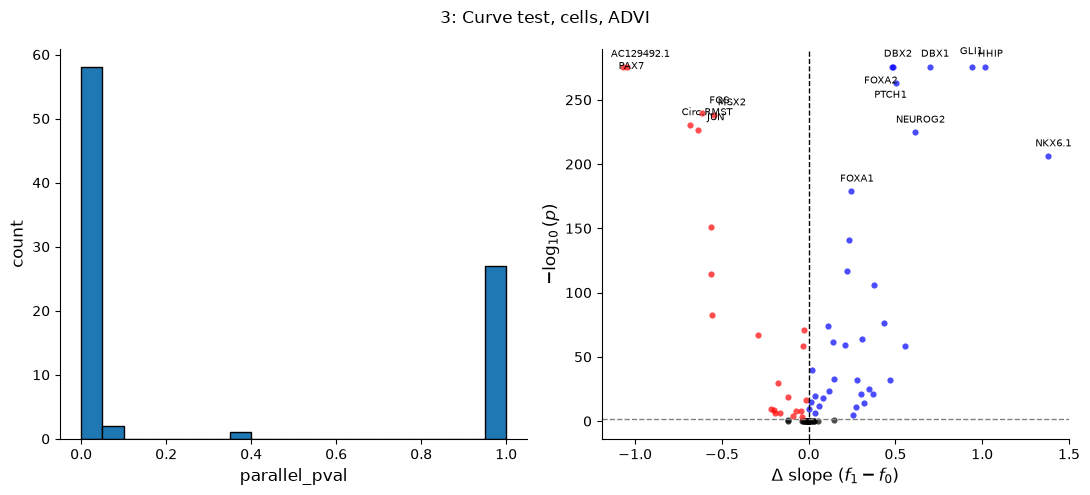

In [10]:
qc_plots(NAME_3, "parallel")

## 4. Curve test on cells, ADVI with empirical-Bayes slide effects

`sample="sample"` adds a random level and a random curve per slide. Their two scales are set per gene by empirical Bayes (the mode of their marginal posterior) and then held fixed while ADVI fits the rest. The p-value uses an F reference with `n_slides - 2` denominator degrees of freedom, so the conditions are compared against the variation between slides rather than between cells. The plotted curves are the population-level ones.

In [11]:
NAME_4 = "4: Curve test, cells, ADVI + EB"
table = run_test(
    NAME_4, "parallel", binning={"window_radius": None, "sample": "sample"},
    use_binned=False, inference="advi", slide_scales="empirical_bayes",
)  # fmt: skip
results[NAME_4][["rank", *COLUMNS["parallel"], "sample_level_sd", "sample_curve_sd", "parallel_df_denominator", "passes_diagnostics"]].head(25)

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models:   1%|          | 1/88 [02:08<3:05:54, 128.21s/it]

/ictstr01/groups/ml01/workspace/laurens.lehner/tools/apps/miniforge/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting DiffSVG models:   2%|▏         | 2/88 [02:26<1:31:18, 63.71s/it] 

Fitting DiffSVG models:   5%|▍         | 4/88 [02:28<34:07, 24.38s/it]  

Fitting DiffSVG models:   6%|▌         | 5/88 [02:31<24:39, 17.83s/it]

... (68 outputs left out)

Fitting DiffSVG models: 100%|██████████| 88/88 [17:45<00:00,  9.03s/it]

Fitting DiffSVG models: 100%|██████████| 88/88 [17:45<00:00, 12.11s/it]

1069 s, 88 of 88 genes pass the diagnostics


,rank,shape_diff,slope_diff,parallel_stat,parallel_pval,parallel_pval_adj,integral,sample_level_sd,sample_curve_sd,parallel_df_denominator,passes_diagnostics
HHIP,1,1.383929,0.910924,138.587858,0.000101,0.008260,-0.085208,0.110451,0.277793,14,True
FOXA2,2,0.812903,0.398578,151.363062,0.000188,0.008260,0.006869,0.044484,0.220541,14,True
GLI1,3,1.172934,0.832966,114.282182,0.000407,0.009571,0.276354,0.096918,0.247893,14,True
PAX7,4,1.485805,-0.905373,93.094307,0.000435,0.009571,-2.115028,0.207073,0.407721,14,True
NEUROG2,5,1.084901,0.370091,66.907812,0.002818,0.049594,0.635596,0.224720,0.313438,14,True
PTCH1,6,1.236054,0.180200,46.780083,0.008887,0.118677,0.145253,0.337613,0.434458,14,True
MSX2,7,0.608092,-0.538885,116.864777,0.009440,0.118677,-0.449460,0.146334,0.110829,14,True
FOXA1,8,0.404139,0.193341,85.321934,0.025010,0.275107,-0.019739,0.029723,0.158258,14,True
DBX2,9,0.974715,0.632142,39.805485,0.030812,0.301272,-0.320880,0.161886,0.321363,14,True
JUN,10,1.165566,-0.645790,29.772037,0.048855,0.425114,-0.284088,0.145933,0.437537,14,True


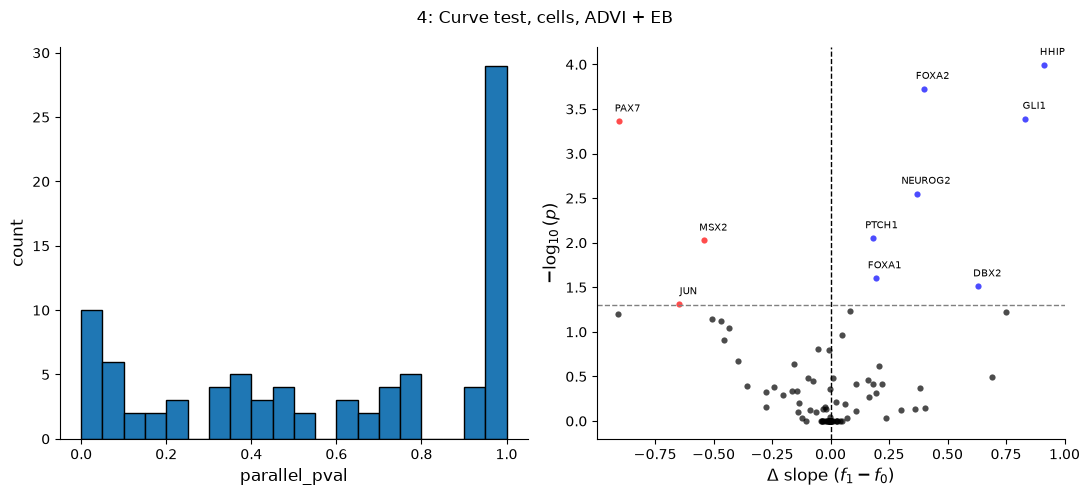

In [12]:
qc_plots(NAME_4, "parallel")

The fits took long, so their tables are saved right away.

In [13]:
pd.to_pickle({"results": results, "timings": timings}, RESULTS_PATH)
RESULTS_PATH

'/lustre/groups/ml01/workspace/laurens.lehner/MA/07_11_results/diffsvg_notebooks/test_comparison_legnini_results.pkl'

## Comparison

### Calls and runtime

How many genes each test flags, and what each one cost. The Wald p-values are not on the same footing as the curve-test ones: the Gamma null treats the lower 90% of the panel as null by construction, so the Wald test can only flag a small part of a panel.

In [14]:
NAMES = list(results)
TEST_OF = {NAME_1: "wald", NAME_2: "parallel", NAME_3: "parallel", NAME_4: "parallel"}

pd.DataFrame(
    {
        name: {
            "p < 0.05": int((results[name][PVALUE[TEST_OF[name]][0]] < 0.05).sum()),
            "BH-adjusted < 0.05": int((results[name][PVALUE[TEST_OF[name]][1]] < 0.05).sum()),
            "pass the diagnostics": int(results[name]["passes_diagnostics"].sum()),
            "minutes": round(timings[name] / 60, 1),
        }
        for name in NAMES
    }
).T

,p < 0.05,BH-adjusted < 0.05,pass the diagnostics,minutes
"1: Wald, bins, NUTS",10.0,5.0,81.0,8.3
"2: Curve test, bins, NUTS",58.0,58.0,85.0,5.2
"3: Curve test, cells, ADVI",58.0,58.0,85.0,4.6
"4: Curve test, cells, ADVI + EB",10.0,5.0,88.0,17.8


### Rank correlation and overlap

Spearman correlation of the ranks over all genes, and the overlap of the top lists. The two say different things: most genes of the panel have no effect, so the lower part of each ranking is mostly noise and the correlation over all genes is partly a correlation of noise. The third matrix therefore repeats the correlation on the genes that are in the top list of at least one of the two tests.

1: Wald, bins, NUTS
2: Curve test, bins, NUTS
3: Curve test, cells, ADVI
4: Curve test, cells, ADVI + EB


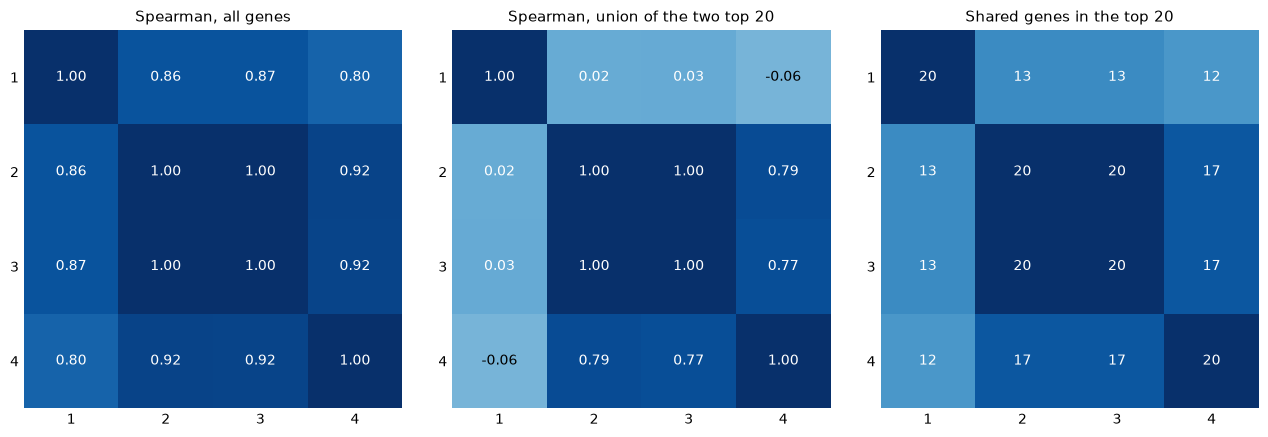

In [15]:
rank_table = pd.DataFrame(ranks).loc[GENES, NAMES]
top = {name: set(rank_table[name].nsmallest(TOP_N).index) for name in NAMES}

spearman = rank_table.corr(method="spearman")
overlap = pd.DataFrame({a: {b: len(top[a] & top[b]) for b in NAMES} for a in NAMES}).loc[NAMES, NAMES]
spearman_top = pd.DataFrame(
    {a: {b: rank_table.loc[sorted(top[a] | top[b]), [a, b]].corr(method="spearman").iloc[0, 1] for b in NAMES} for a in NAMES}
).loc[NAMES, NAMES]


def heatmap(ax, matrix, title, vmin, vmax, fmt):
    """Annotated matrix on one sequential scale; every cell carries its value."""
    ax.imshow(matrix.to_numpy(dtype=float), cmap="Blues", vmin=vmin, vmax=vmax)
    labels = [name.split(":")[0] for name in matrix.columns]
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_title(title, fontsize=11)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    midpoint = (vmin + vmax) / 2
    for i, j in np.ndindex(matrix.shape):
        value = float(matrix.iloc[i, j])
        ax.text(j, i, format(value, fmt), ha="center", va="center", fontsize=10, color="white" if value > midpoint else "black")


fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
heatmap(axes[0], spearman, "Spearman, all genes", 0, 1, ".2f")
heatmap(axes[1], spearman_top, f"Spearman, union of the two top {TOP_N}", -1, 1, ".2f")
heatmap(axes[2], overlap, f"Shared genes in the top {TOP_N}", 0, TOP_N, ".0f")
fig.tight_layout()
print("\n".join(NAMES))

### Rank against rank

Every pair of tests, with the genes that move most labelled. Genes near the diagonal rank the same in both.

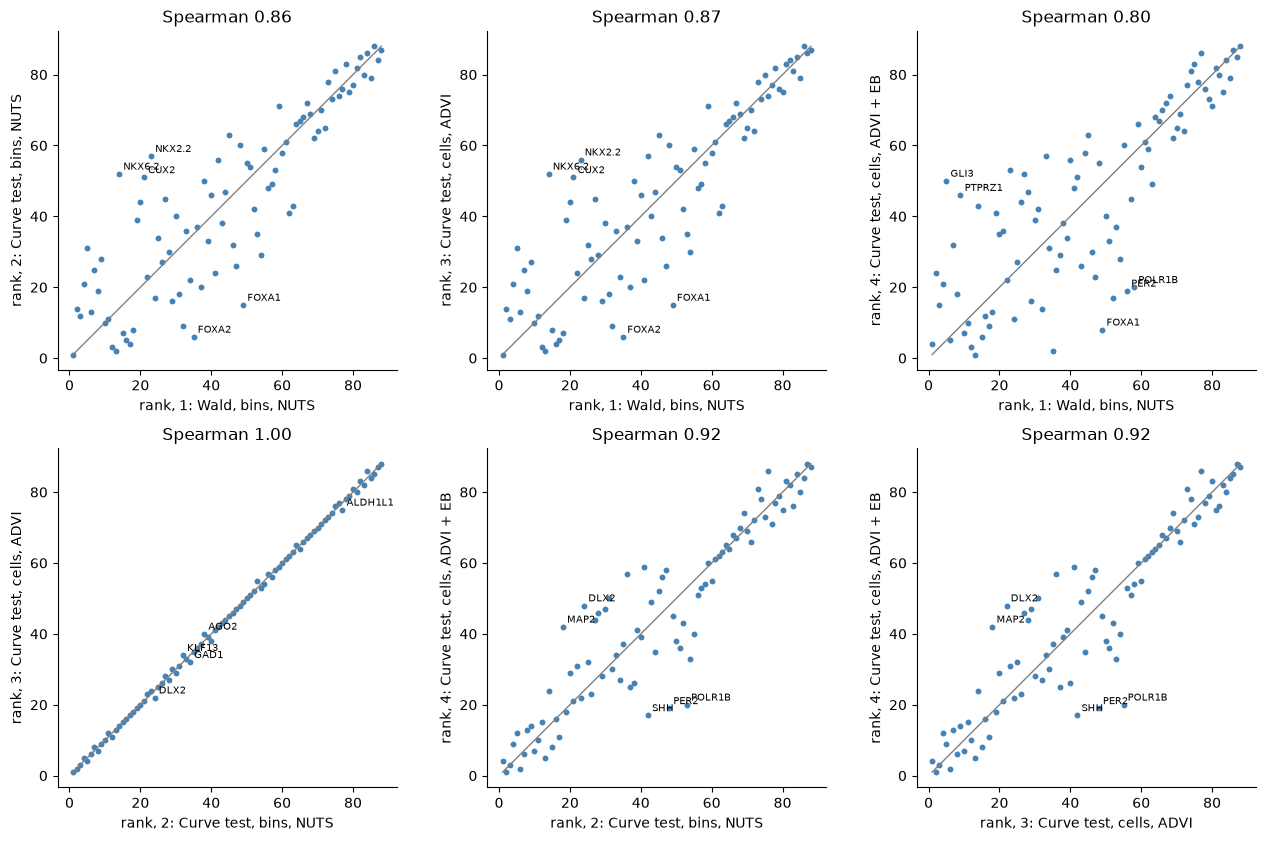

In [16]:
PAIRS = [(a, b) for i, a in enumerate(NAMES) for b in NAMES[i + 1 :]]
N_MOVERS = 5

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, (a, b) in zip(axes.ravel(), PAIRS, strict=True):
    x, y = rank_table[a], rank_table[b]
    ax.plot([1, len(x)], [1, len(x)], color="grey", lw=1)
    ax.scatter(x, y, s=18, color="steelblue", linewidth=0)
    for gene in (x - y).abs().nlargest(N_MOVERS).index:
        ax.annotate(gene, (x[gene], y[gene]), xytext=(3, 3), textcoords="offset points", fontsize=7)
    ax.set(xlabel=f"rank, {a}", ylabel=f"rank, {b}", title=f"Spearman {spearman.loc[a, b]:.2f}", aspect="equal")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()

### Why Wald and the curve test disagree

`T` is the mean squared gap between the curves, so it splits into the squared level difference and the part from the shape: `T = integral^2 + shape_diff^2 / 12`. The first plot shows how much of `T` is level for every gene of the Wald fit. If the gap is mostly level, the Wald test can rank a gene highly although the curves run parallel, and the curve test will not flag it. The second plot checks whether this explains the disagreement: rank under the curve test minus rank under Wald, against the share of level in `T`.

Spearman, level share vs. rank shift: 0.78


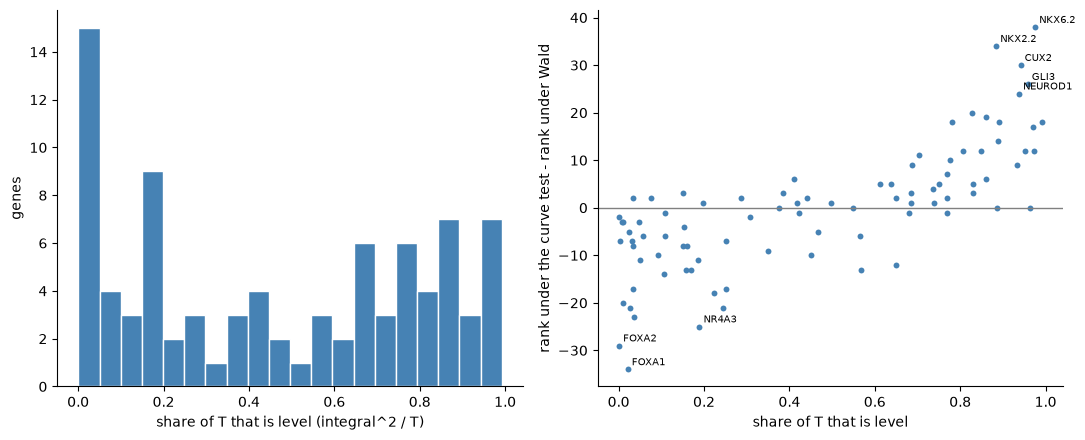

In [17]:
wald, curve = results[NAME_1], results[NAME_2].loc[results[NAME_1].index]
level_share = (wald["integral"] ** 2 / wald["T"]).clip(upper=1)
rank_shift = curve["rank"] - wald["rank"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(level_share, bins=20, color="steelblue", edgecolor="white")
axes[0].set(xlabel="share of T that is level (integral^2 / T)", ylabel="genes")
axes[1].axhline(0, color="grey", lw=1)
axes[1].scatter(level_share, rank_shift, s=18, color="steelblue", linewidth=0)
for gene in rank_shift.abs().nlargest(8).index:
    axes[1].annotate(gene, (level_share[gene], rank_shift[gene]), xytext=(3, 3), textcoords="offset points", fontsize=7)
axes[1].set(xlabel="share of T that is level", ylabel="rank under the curve test - rank under Wald")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
print(f"Spearman, level share vs. rank shift: {level_share.corr(rank_shift, method='spearman'):.2f}")

### What the slide effects change

The same fit with and without slide effects (tests 3 and 4). Slide effects leave the effect size roughly in place, because they mostly change how much the data say about it, so a gene whose difference comes from a few slides keeps its `shape_diff` and loses its significance. The table lists the genes flagged without slide effects that are no longer flagged with them.

,"shape_diff, no slides","shape_diff, EB","p, EB",curve sd between slides
PTCH1,1.441,1.236,0.009,0.434
MSX2,0.653,0.608,0.009,0.111
FOXA1,0.536,0.404,0.025,0.158
DBX2,0.934,0.975,0.031,0.321
JUN,1.331,1.166,0.049,0.438
PROM1,0.989,0.891,0.058,0.373
DBX1,1.289,1.241,0.060,0.536
AC129492.1,1.272,1.020,0.063,0.389
FOS,0.971,0.749,0.073,0.272
Circ.RMST,1.382,1.054,0.076,0.559


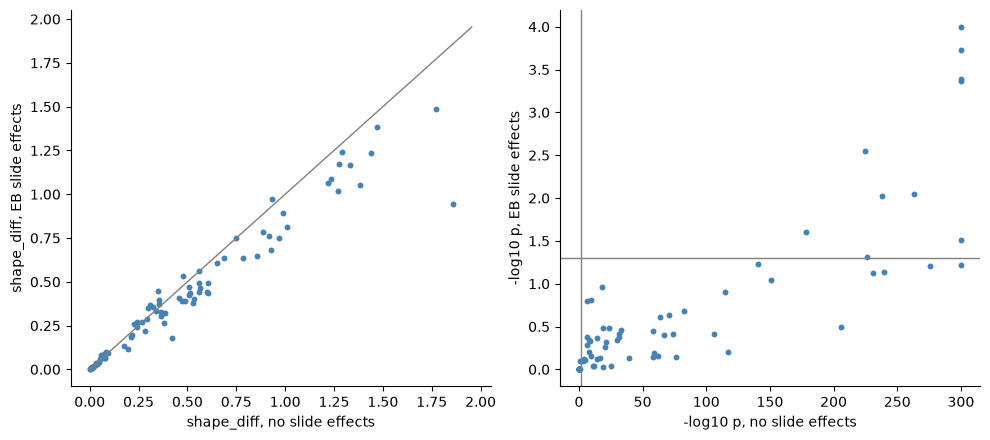

In [18]:
pooled, slides = results[NAME_3], results[NAME_4].loc[results[NAME_3].index]
floor = 1e-300

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
limit = 1.05 * float(max(pooled["shape_diff"].max(), slides["shape_diff"].max()))
axes[0].plot([0, limit], [0, limit], color="grey", lw=1)
axes[0].scatter(pooled["shape_diff"], slides["shape_diff"], s=18, color="steelblue", linewidth=0)
axes[0].set(xlabel="shape_diff, no slide effects", ylabel="shape_diff, EB slide effects")
axes[1].axhline(-np.log10(0.05), color="grey", lw=1)
axes[1].axvline(-np.log10(0.05), color="grey", lw=1)
axes[1].scatter(
    -np.log10(pooled["parallel_pval"].clip(lower=floor)),
    -np.log10(slides["parallel_pval"].clip(lower=floor)),
    s=18, color="steelblue", linewidth=0,
)  # fmt: skip
axes[1].set(xlabel="-log10 p, no slide effects", ylabel="-log10 p, EB slide effects")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()

lost = (pooled["parallel_pval_adj"] < 0.05) & (slides["parallel_pval_adj"] >= 0.05)
pd.DataFrame(
    {
        "shape_diff, no slides": pooled.loc[lost, "shape_diff"],
        "shape_diff, EB": slides.loc[lost, "shape_diff"],
        "p, EB": slides.loc[lost, "parallel_pval"],
        "curve sd between slides": slides.loc[lost, "sample_curve_sd"],
    }
).sort_values("p, EB").round(3)

### The genes the tests disagree on most

The curves of the three genes with the largest spread in rank over the four tests, from the slide model. The bands hold the noise of a single cell or bin, so they are wider than the uncertainty of the curve itself: judge the difference by the test and the mean curves, not by whether the bands overlap.

,"1: Wald, bins, NUTS","2: Curve test, bins, NUTS","3: Curve test, cells, ADVI","4: Curve test, cells, ADVI + EB",spread
GLI3,5,31,31,50,45
FOXA1,49,15,15,8,41
NKX6.2,14,52,52,43,38


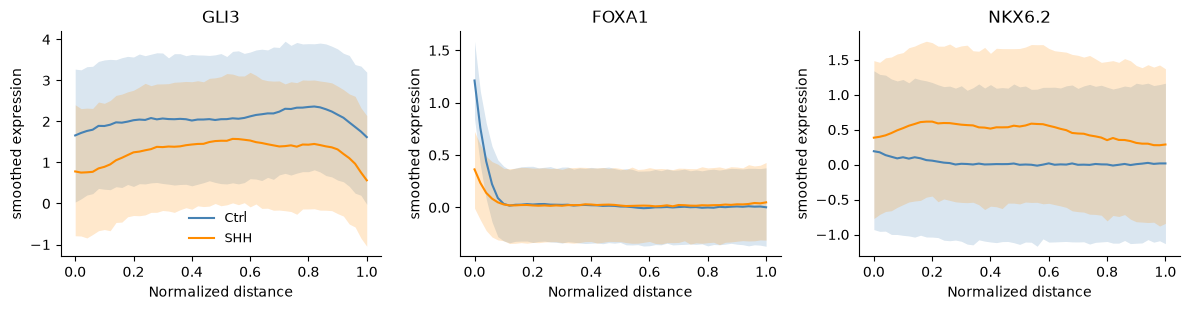

In [19]:
spread = rank_table.max(axis=1) - rank_table.min(axis=1)
disputed = spread.nlargest(3).index
display(rank_table.loc[disputed].assign(spread=spread[disputed]))
dvg.pl.plot_prediction_curve(adata, gene=list(disputed), curves_key="test4_curves", ncols=3);